In [31]:
import pandas as pd
import numpy as np
import math
from PIL import Image
from matplotlib import pyplot as plt

In [32]:
#img = np.asarray(Image.open("chelovechki/1.png").convert("L")) / float(255.0)
#print(img)

In [33]:
df = pd.DataFrame({
    'y' : [0] * 0,
    'et': [0] * 0,
    'er': [0] * 0
})

print(df)



Empty DataFrame
Columns: [y, et, er]
Index: []


In [34]:
def sigma(x):
  res = 0
  if x > 700:
    res = 1
  elif x < -700:
    res = 0
  else: 
    res = 1 / (1 + math.exp(-x))
  return res
def porog(x):
  res = 0
  if x >= 0:
    res = 1
  return res

neironcount = 0

class akson:
  def __init__(self):
    self.wes = 0
  def __repr__(self):
    return str(self.wes)

class neiron:
  def __init__(self):
      global neironcount
      self.aksons = []
      self.neirons = []
      self.id = neironcount
      neironcount += 1
      self.lastvalue = 0
  def getvalue(self):
    f = 0
    for i in range(len(self.neirons)):
      f += self.aksons[i].wes * self.neirons[i].getvalue()
    res = sigma(f)
    self.lastvalue = res
    return res

class inputneiron(neiron):
  def setvalue(self, x):
    self.myvalue = x
  def getvalue(self):
    #print(f"в нейроне {self.id} значение {self.myvalue} x")
    self.lastvalue = self.myvalue
    return self.myvalue
  def __init__(self):
    super().__init__()
    self.myvalue = 0

class outputneiron(neiron):
  def getvalue(self):
    f = 0
    for i in range(len(self.aksons)):
      f += self.aksons[i].wes * self.neirons[i].getvalue()
    res = porog(f)
    self.lastvalue = res
    return res

In [35]:
import random

layer1 = [inputneiron() for i in range(36)]
layer2 = [neiron() for i in range(6)]
layer3 = outputneiron()
biasneiron = inputneiron()
biasneiron.setvalue(1)
neironsall = layer1 + layer2 + [layer3]
aksonsall = []

layer1.append(biasneiron)
layer2.append(biasneiron)
layer3.neirons.append(biasneiron)

for n in layer2:
  n.neirons = layer1
  for j in range(len(layer1)):
    n.aksons.append(akson())

layer3.neirons = layer2
for j in range(len(layer2)):
  layer3.aksons.append(akson())

for n in neironsall:
  for a in n.aksons:
    a.wes = random.uniform(-1, 1)
    aksonsall.append(a)

for a in aksonsall:
  a.wes = random.uniform(-1, 1)

In [36]:
def showwesa():
  for a in aksonsall:
    print(a.wes)
#print(aksonsall)
#showwesa()
print(aksonsall)

[0.560887904120773, 0.8391597808191231, 0.842997334776435, -0.08733788914697915, 0.5527889238966261, -0.3140863554270559, -0.4285442614741324, 0.6745620016603693, -0.07423964433905472, -0.5534573019107536, 0.5707037242983937, -0.6226722476124908, 0.2744461953184041, 0.8631754673250507, -0.5608613708424759, -0.09786099376335144, 0.6346055467946496, 0.17682545251993576, -0.5053047139524929, 0.14969351886405202, 0.18268387118906193, 0.5785239252296666, 0.004674013662210541, 0.5583588814501999, -0.9593438839146344, -0.07933788141469189, 0.18232433388834668, -0.6471445516591643, -0.16832831392638292, 0.7528247089172801, -0.8291475055546242, -0.6093243438957343, 0.06251521339809152, -0.848341736493307, 0.7778461387928268, -0.24306725820085195, 0.5535729566502441, 0.43184334077715625, -0.006750438750528387, 0.7898510070435378, -0.03898151049258969, -0.4605729863385106, 0.7047788598555631, -0.4243952414705372, 0.2457034425023632, -0.8789003753083353, -0.4710641265278639, -0.5802601926010267, -

Теперь надо разобраться с загрузкой датасета и использованием изображений из папки chelovechki

In [37]:
import requests
import os
'''
## Set the GitHub repository and folder details
repo_url = "https://api.github.com/repos/ashotnafig1/Neironki/contents/Lab02/chelovechki"
local_path = "chelovechki"

os.makedirs(local_path, exist_ok=True)
## Send a GET request to the GitHub API
response = requests.get(repo_url)

## Iterate through the folder contents and download each file
for item in response.json():
    if item["type"] == "file":
        file_url = item["download_url"]
        file_name = item["name"]
        file_path = f"{local_path}/{file_name}"

        ## Download the file
        file_response = requests.get(file_url)
        with open(file_path, "wb") as file:
            file.write(file_response.content)
'''

'\n## Set the GitHub repository and folder details\nrepo_url = "https://api.github.com/repos/ashotnafig1/Neironki/contents/Lab02/chelovechki"\nlocal_path = "chelovechki"\n\nos.makedirs(local_path, exist_ok=True)\n## Send a GET request to the GitHub API\nresponse = requests.get(repo_url)\n\n## Iterate through the folder contents and download each file\nfor item in response.json():\n    if item["type"] == "file":\n        file_url = item["download_url"]\n        file_name = item["name"]\n        file_path = f"{local_path}/{file_name}"\n\n        ## Download the file\n        file_response = requests.get(file_url)\n        with open(file_path, "wb") as file:\n            file.write(file_response.content)\n'

In [38]:
# возвращает np массив изображения, причём нормализованный
def readimage(path):
    return np.asarray(Image.open(path).convert("L")) / float(255.0) 

tablefull = pd.read_csv("chelovechki/tablica.txt", sep=' ')
tablefull["y"] = None
tablefull["err"] = None

print(tablefull)

table = tablefull.sample(frac = 0.8, random_state = 228)
tabletest = tablefull.drop(table.index)

def getimage(number):
    return readimage("chelovechki/" + str(number) + ".png").flatten()
for i in range(len(table)):
    print(getimage(i))

    id  class     y   err
0    0      1  None  None
1    1      1  None  None
2    2      1  None  None
3    3      1  None  None
4    4      0  None  None
5    5      1  None  None
6    6      0  None  None
7    7      1  None  None
8    8      0  None  None
9    9      0  None  None
10  10      1  None  None
11  11      0  None  None
12  12      0  None  None
13  13      1  None  None
14  14      0  None  None
15  15      0  None  None
16  16      0  None  None
17  17      1  None  None
18  18      0  None  None
19  19      0  None  None
20  20      0  None  None
21  21      1  None  None
22  22      1  None  None
23  23      1  None  None
24  24      1  None  None
25  25      0  None  None
26  26      0  None  None
27  27      1  None  None
28  28      0  None  None
29  29      1  None  None
30  30      1  None  None
31  31      0  None  None
[0. 0. 0. 1. 0. 0. 0. 1. 0. 1. 1. 0. 0. 0. 1. 1. 0. 1. 0. 0. 0. 1. 0. 0.
 0. 0. 1. 0. 1. 0. 0. 1. 0. 0. 0. 1.]
[0. 0. 1. 0. 0. 0. 1. 0. 1. 1. 

[0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 1. 1. 0. 0. 0. 0. 1. 0. 0. 0.
 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 0. 1. 1. 0. 0. 0. 1. 1. 1. 1. 0. 0. 1. 1. 1. 1. 0. 0. 1. 1. 1. 1.
 0. 0. 0. 1. 1. 0. 0. 0. 0. 1. 1. 0.]
[0. 0. 1. 0. 0. 0. 0. 1. 1. 0. 1. 0. 1. 0. 1. 1. 0. 0. 0. 0. 1. 0. 0. 0.
 0. 1. 0. 1. 0. 0. 1. 0. 0. 0. 1. 0.]
[0. 1. 0. 0. 0. 0. 1. 1. 1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 1. 1. 0. 0. 0. 0. 1. 0. 0. 0.
 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 1. 1. 0. 0. 0.
 0. 1. 0. 0. 0. 0. 1. 0. 1. 0. 0. 0.]
[0. 0. 1. 1. 0. 0. 0. 1. 1. 1. 1. 0. 0. 1. 1. 1. 1. 0. 0. 1. 1. 1. 1. 0.
 0. 0. 1. 1. 0. 0. 0. 0. 1. 1. 0. 0.]
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 1. 1. 0. 0. 0. 0. 1. 0.
 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 1. 0. 0. 0. 0. 1. 1. 1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 0. 1. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
[

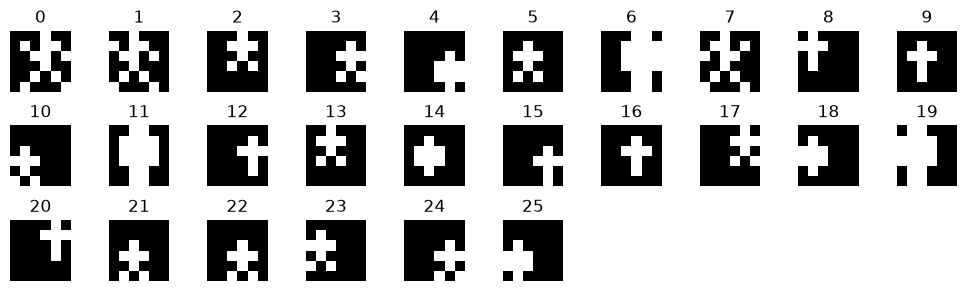

In [39]:
imagescount = len(table)
cols = 10
rows = math.ceil(imagescount / cols)
fig, axes = plt.subplots(rows, cols, figsize=(cols, rows))
axes = axes.flatten() 
for i in range(min(imagescount, 40)):
    img = Image.open("chelovechki/" + str(i) + ".png").convert("L")
    axes[i].imshow(img, cmap="gray")
    axes[i].set_title(f"{i}")
    axes[i].axis('off')
for j in range(imagescount, len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()


In [40]:
#
def Test(X):
  for i in range(len(X)):
    layer1[i].setvalue(X[i])
  return layer3.getvalue()


In [41]:
def bigtest():
  s = 0
  sq = 0
  for i, clas in table.iterrows():
    X = getimage(i)
    y_pred = Test(X)
    table.loc[i, "y"]  = y_pred
    table.loc[i, "err"] = table.loc[i, "class"] - y_pred
    s += table.loc[i, "err"]
    sq += (table.loc[i, "err"])**2
  return float(s), float(sq)

summa, summaq = bigtest()
print(summa, summaq)
print(table)

-12.0 12.0
    id  class  y err
4    4      0  1  -1
6    6      0  1  -1
22  22      1  1   0
13  13      1  1   0
8    8      0  1  -1
14  14      0  1  -1
2    2      1  1   0
11  11      0  1  -1
0    0      1  1   0
30  30      1  1   0
9    9      0  1  -1
27  27      1  1   0
7    7      1  1   0
15  15      0  1  -1
31  31      0  1  -1
17  17      1  1   0
1    1      1  1   0
29  29      1  1   0
10  10      1  1   0
21  21      1  1   0
18  18      0  1  -1
28  28      0  1  -1
20  20      0  1  -1
3    3      1  1   0
26  26      0  1  -1
23  23      1  1   0


Всё готово, можно пробовать делать обучение


In [42]:
param = 0.35


#showwesa()

In [43]:

#def korrektirowka():
#  for i, row in df.iterrows():


In [44]:
# это пайтон версия обучения с корректировкой
'''
epohi = 0
while (summaq != 0) and (epohi < 1000):
  correctwesa()
  summa, summaq = bigtest()
  epohi += 1

print(aksonsall)
print("эпох: " + str(epohi))
print(table)
'''

'\nepohi = 0\nwhile (summaq != 0) and (epohi < 1000):\n  correctwesa()\n  summa, summaq = bigtest()\n  epohi += 1\n\nprint(aksonsall)\nprint("эпох: " + str(epohi))\nprint(table)\n'

In [45]:
# neir это испытуемый нейрон
# i это локальный индекс испытуемого веса (и нейрона на другой стороне тоже)
# BIGerror это квадратичная ошибка
# чтобы не вычислять каждый раз ошибку внутри функции
# её лучше в параметр передавать
# !!! Функция выведена из эксплуатации
def getdldw(neir, i, BIGerror):
    y = neir.lastvalue
    x = neir.neirons[i].lastvalue
    res = BIGerror * y * (1 - y) * x
    return res

def getBIGerror():
    s = 0
    sq = 0
    for i, clas in table.iterrows():
        X = getimage(i)
        y_pred = Test(X)
        table.loc[i, "y"]  = y_pred
        table.loc[i, "err"] = table.loc[i, "class"] - y_pred
        s += table.loc[i, "err"]
        sq += (table.loc[i, "err"])**2
    return float(s), float(sq)
    

In [46]:
# опять поставлю на выходной нейрон сигмоиду чтобы красиво работало
def getvaluePOROG(self):
    f = 0
    for i in range(len(self.aksons)):
      f += self.aksons[i].wes * self.neirons[i].getvalue()
    res = porog(f)
    self.lastvalue = res
    return res

def getvalueSIGMO(self):
    f = 0
    for i in range(len(self.neirons)):
      f += self.aksons[i].wes * self.neirons[i].getvalue()
    res = sigma(f)
    self.lastvalue = res
    return res

outputneiron.getvalue = getvalueSIGMO


всё что выше была заготовка самих данных, алгоритма обучения и способов как это связать.
Пора проверять чё я там настрочил

In [47]:
maloe = 10e-4
speed = 0.1

epohi = 0
bigerrors = []
BIG, BIGQ = getBIGerror()
while BIGQ > maloe and epohi < 2000:
    for i, clas in table.iterrows():
        X = getimage(i)
        y = Test(X)
        e = table.loc[i, "class"]
        n3 = layer3
        for i in range(len(n3.neirons)):
            n2 = n3.neirons[i]
            n3.aksons[i].wes -= (e - y) * n3.lastvalue * (n3.lastvalue - 1) * n2.lastvalue * speed
            for j in range(len(n2.neirons)):
                n1 = n2.neirons[j]
                # смешная производная, я комментами опишу где какая часть
                n2.aksons[j].wes += ((e - y) *                              # производная квадратичной ошибки по y
                                     n3.lastvalue * (n3.lastvalue - 1) *    # производная сигмоиды по сумме на n3
                                     n3.aksons[i].wes *                     # производная суммы по одному из входов
                                     n2.lastvalue * (n2.lastvalue - 1) *    # производная сигмоиды на скрытом нейроне
                                     n1.lastvalue *                         # производная суммы по весу
                                     speed)                                 # просто параметр от 0 до 1
            
    BIG, BIGQ = getBIGerror()
    bigerrors.append(BIGQ)
    epohi += 1
bigerrors.append(BIGQ)

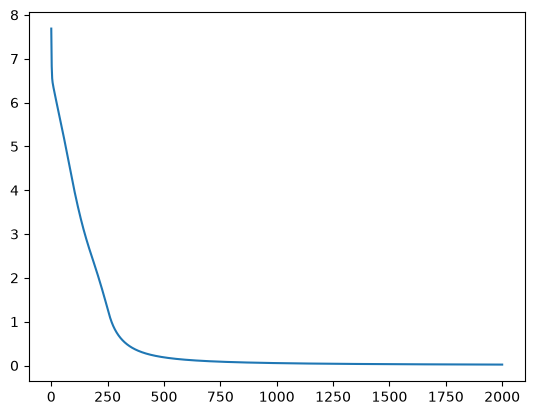

In [48]:

plt.plot(np.arange(0, epohi + 1), bigerrors)

In [49]:
#print(table)
#showwesa()
print(aksonsall)
with open("wesaBACKPRO.txt", "w") as file:
    for a in aksonsall:
        file.write(str(a) + '\n')


[0.560887904120773, 0.48709547045960194, 0.5431480655397402, -0.12893346103147138, 1.273542217401677, -0.3140863554270559, -1.1217583572711483, 0.13809049388730232, -0.3216571103749534, -0.8210446119684061, 1.0040749793153385, -0.3628332026743768, 0.03713185906298621, 1.103824104713985, 0.11976228241382947, 0.1439353373209072, 1.1466107387757833, 0.06805636962514845, -0.8317022300707283, 0.5125583944328804, -0.2979497236295363, 0.42655119462010915, -0.06654122440143148, 0.7900986364249405, -1.3867134367551428, 0.15037416101138176, -0.5925115471085332, -0.9846826248945868, -0.4580679370656515, 0.4749247866588655, -1.5528373804664752, -0.6696439400028696, -0.23433750741385434, -0.6918983176736045, 0.7550822905941674, -0.7410440036363528, 0.05874717492226504, 0.43184334077715625, 0.6080605536212268, 0.5424363022455788, 0.13431787115958255, -1.1395259356967589, 0.7047788598555631, 0.8011027513508044, -0.026755257276709167, -0.41248767218044347, -0.476709926509205, 0.049747062646692604, -1.

In [50]:
outputneiron.getvalue = getvaluePOROG
getBIGerror()
#print(table)
#showwesa()

acc = 0.0
for i, clas in tabletest.iterrows():
    X = getimage(i)
    y_pred = Test(X)
    if tabletest.loc[i, "class"] == y_pred:
        acc += 1
print(acc / float(len(tabletest)))

0.3333333333333333


In [51]:
print(len(aksonsall))
print("это столько весов")

229
это столько весов


Теперь метод коррекции будет

In [52]:
for a in aksonsall:
    a.wes = random.uniform(-1, 1)

def correctwesa(eror):
    for n in neironsall:
        for a in n.aksons:
            a.wes -= eror * n.getvalue() * param * random.choice((-1, 1))


outputneiron.getvalue = getvalueSIGMO
summa, summaq = bigtest()
print(summa, summaq)
print(table)


-0.8612111986882969 6.663338040400162
    id  class         y       err
4    4      0  0.430643 -0.430643
6    6      0  0.564702 -0.564702
22  22      1  0.571598  0.428402
13  13      1  0.675013  0.324987
8    8      0  0.545768 -0.545768
14  14      0  0.664453 -0.664453
2    2      1  0.532513  0.467487
11  11      0  0.652033 -0.652033
0    0      1  0.546265  0.453735
30  30      1  0.517977  0.482023
9    9      0   0.63975  -0.63975
27  27      1   0.37753   0.62247
7    7      1  0.692861  0.307139
15  15      0  0.365588 -0.365588
31  31      0  0.682276 -0.682276
17  17      1  0.463097  0.536903
1    1      1   0.74109   0.25891
29  29      1  0.539819  0.460181
10  10      1  0.632103  0.367897
21  21      1  0.611162  0.388838
18  18      0   0.66193  -0.66193
28  28      0  0.599499 -0.599499
20  20      0  0.441087 -0.441087
3    3      1  0.616324  0.383676
26  26      0  0.577591 -0.577591
23  23      1  0.518541  0.481459


In [53]:
# обучение с корректировкой и случайным знаком (фигня полная)
epohi2 = 0
bigerrors2 = []
summaq = 1
while (summaq > maloe) and (epohi2 < 500):
    for i, clas in table.iterrows():
          X = getimage(i)
          y = Test(X)
          e = table.loc[i, "class"]
          correctwesa(e - y)
    summa, summaq = getBIGerror()
    bigerrors2.append(summaq)
    epohi2 += 1
bigerrors2.append(summaq)
print(aksonsall)
print("эпох: " + str(epohi2))
print(table)

[-8.241202593060418, 25.823450608677806, -2.522668556690162, -25.032526106876468, -14.144814187476886, -3.5657027528331264, 34.67305708105918, 4.391727405007034, -4.416567252149605, 9.656954338683882, 7.948301254231708, 4.442895457510966, 19.53317665868139, -2.6084423686546403, 15.186317025636354, -56.16509344712636, -4.231938117010604, -17.874439363416176, -9.33340769620551, 5.429225084477162, 20.18867620318093, -16.327691917680063, 8.94544124369807, -18.133618693636617, -10.988192027954145, -27.31802470837792, -12.161237699100791, -3.306251050236375, 30.951872628274895, 3.4235470168922353, 3.83581549748075, 4.907619688215081, 22.24547579349984, 20.082568593918932, 26.266958525343004, -12.57333933407215, -15.716536354747353, 8.306294220889704, -5.446703218549192, -12.990418063891461, -12.536724265391186, -31.35408796365828, 8.368621695625997, 4.28170858898343, -9.040120882367658, 20.276778486250258, -24.028513745343815, -7.324886691624752, -13.711469800063005, -23.481978845530982, -7.

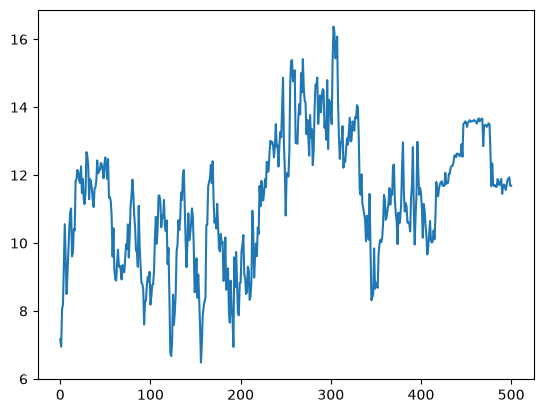

In [54]:
plt.plot(np.arange(0, epohi2 + 1), bigerrors2)

обучение с рандомным подкреплением уже обречено на провал, а метод коррекции корректен только для выходного слоя

для GUI верну веса полученные бекпропом

In [55]:

with open("wesaBACKPRO.txt", "r") as file:
    line = file.readline()
    i = 0
    while line:
        aksonsall[i].wes = float(line)
        i += 1
        line = file.readline()

In [56]:
outputneiron.getvalue = getvaluePOROG
BIG, BIGQ = getBIGerror()
print(BIGQ)

0.0


In [58]:
# ИНТЕРФЭЭЭЙС
%gui qt6

import sys
from PyQt6 import QtWidgets as qw

allbuttons = []
class krutayaknopka(qw.QPushButton):
    def __init__(self, text, myvalue, parent = ...):
        super().__init__()
        self.myvalue = myvalue
        self.activated = 1
        self.selectcolor()
        self.clicked.connect(self.selectcolor)
    def selectcolor(self):
        if self.activated == 0:
            self.activated = 1
            self.setStyleSheet("background-color: #FFFFFF")
        else:
            self.activated = 0
            self.setStyleSheet("background-color: #000000")
        self.delegat()
    def delegat(self):
        return

class krutoeokno(qw.QMainWindow):
    def __init__(self):
        super().__init__()
        razmer = 6

        layout = qw.QHBoxLayout()
        self.label = qw.QLabel("sadsadsad")
        layout.addWidget(self.label)
        grid = qw.QGridLayout()
        gridwidget = qw.QWidget()
        gridwidget.setFixedSize(50 * razmer, 50 * razmer)
        gridwidget.setLayout(grid)
        layout.addWidget(gridwidget)

        for row in range(razmer):
            for col in range(razmer):
                b = krutayaknopka("", row * razmer + col)
                b.setFixedSize(50, 50)
                allbuttons.append(b)
                grid.addWidget(b, row, col)
                
        
        self.setWindowTitle("акошко")
        self.setGeometry(100, 50, 800, 500)
        container = qw.QWidget()
        container.setLayout(layout)
        self.setCentralWidget(container)
        
window = krutoeokno()

def predictevent(kacherishka):
    X = [float(b.activated) for b in allbuttons]
    y = Test(X)
    if y == 0:
        window.label.setText("стоит")
    else:
        window.label.setText("идёт")
krutayaknopka.delegat = predictevent

window.show()